# Storyline 4: Outside four immigration-related units, backlog has risen in stages relative to receipts

This storyline looks at requests not yet closed: **is backlog growing in step with receipts, or faster than receipts, and where?**

**The finding in one sentence (Section 9):** outside USCIS, CBP, ICE and EOIR, year-end backlog relative to annual receipts climbed from about 10% in FY2011–13 to 26.0% in FY2020–25; the FY2020–25 average is 9.1 points above FY2014–19, and at least 8.0 points after removing any single unit. The rise is mainly within agencies and broad: of the 96 agencies with data in every year from FY2014 to FY2025, 69 have a higher ratio. The government-wide ratio rose only about 3 points because the four units have low ratios and a growing share of receipts.

**Roadmap:**

| Section | Question | Finding |
|---|---|---|
| 1 | Do counts and ratios tell the same story? | Counts rise; the ratio goes up and down |
| 2 | Why does the government-wide ratio barely move? | The four units' low ratios and growing weight dilute the rise elsewhere |
| 3 | What happens outside the four units? | A rise in stages since about FY2013 (five down years out of twelve), steepest in FY2020; it remains without DOS |
| 4 | Is it broad? | Seven to eight in ten agencies rose, mainly within agencies |
| 5 | Where do the FY2020 jump and the FY2023–24 dip come from? | Mainly swings in a few units' receipts (NARA, PRIV, VBA) |
| 6 | Does a second measure agree? | Pending at year end / receipts moves the same way; backlog stays a steady share of pending requests; on a perfected-only denominator the increase is larger |
| 7 | How much higher, and how robust? | 9.1 points on average, at least 8.0 after any removal, and it survives prior-year figures |
| 8 | Where is the backlog? | Almost half of FY2025 government backlog is at CBP, PRIV and DOS Main |
| 9 | The resulting story | One sentence, key points, what not to say, leads, methods |

**Abbreviations and terms:**

| Abbreviation | Full name |
|---|---|
| USCIS, CBP, ICE | U.S. Citizenship and Immigration Services; U.S. Customs and Border Protection; U.S. Immigration and Customs Enforcement (all in DHS) |
| EOIR | Executive Office for Immigration Review (DOJ; the immigration courts) |
| PRIV | DHS Privacy Office |
| VBA | Veterans Benefits Administration (VA) |
| NARA | National Archives and Records Administration |
| DHS, DOJ, DOS, DoD, HHS, DOT, DOL, VA | Departments of Homeland Security, Justice, State, Defense, Health and Human Services, Transportation, Labor, and Veterans Affairs |
| EEOC, SSA, SEC | Equal Employment Opportunity Commission; Social Security Administration; Securities and Exchange Commission |

Terms: **the four units** are USCIS, CBP, ICE and EOIR, a grouping of units, not of request topics. **Backlog** is Table 26 year-end backlog: requests still open at year end past the statutory deadline, which runs from receipt of a perfected request (one that reasonably describes the records and can be processed); receipts count all requests, perfected or not (handbook, Section XII.A and Section V). **Receipts** are requests received in the year (Table 01); **pending at year end** is requests still open at year end, whether or not past the deadline (Table 01). "Points" means percentage points.

## 1. Do counts and ratios tell the same story?

First, the government-wide backlog count and backlog ÷ receipts. The ratio sets the year-end stock beside the year's inflow; it is not the probability that a request received that year became backlogged.

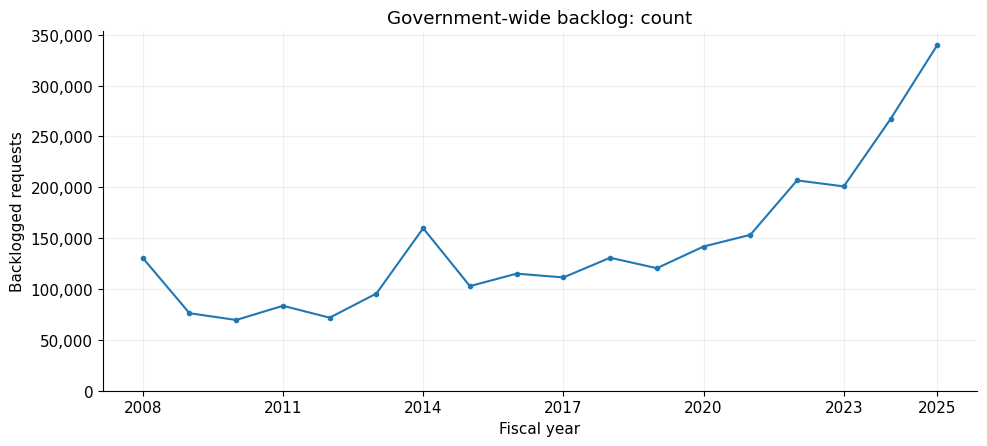

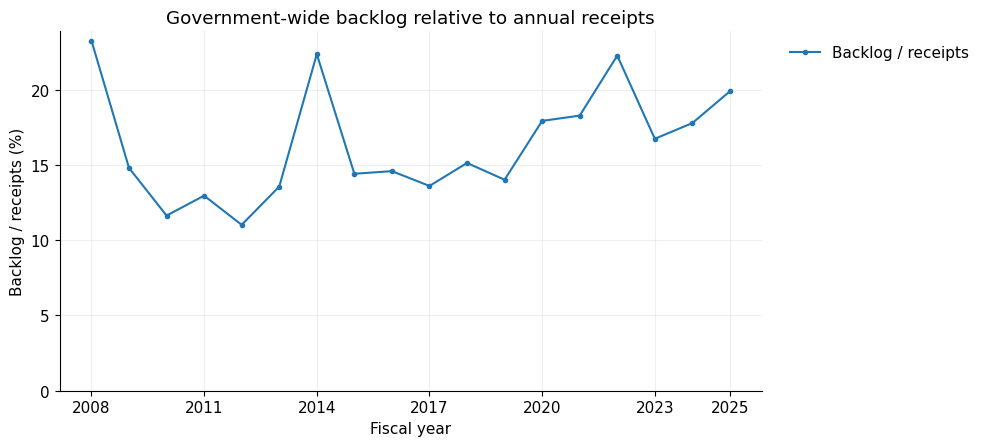

,Backlog,Receipts,Backlog / receipts (%)
2008,130535,560978,23.3
2009,76170,514478,14.8
2010,69526,597415,11.6
2011,83490,644165,13.0
2012,71790,651254,11.0
2013,95564,704394,13.6
2014,159741,714231,22.4
2015,102828,713168,14.4
2016,115080,788769,14.6
2017,111344,818272,13.6


In [1]:
from storyline_lib import *
from IPython.display import display
import ast
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D
PEND=col('01','PendingAtEnd')                      # requests pending at year end (Table 01)
imm=lambda r:not ni(r)                             # the four units: USCIS, CBP, ICE, EOIR
isNARA=lambda r:AGK(r)=='NARA'
isPRIV=lambda r:AGK(r)=='DHS' and r['Component']=='PRIV'
isCISA=lambda r:AGK(r)=='DHS' and r['Component']=='CISA'
isPC=lambda r:isPRIV(r) or isCISA(r)               # one stream of requests: under CISA through FY2018, under PRIV from FY2019 (Storyline 0, Section 3)
# Agencies without components appear twice in the removal list (as the agency and as their only component); keep one copy
units_by_ag=defaultdict(set)
for r in G: units_by_ag[AGK(r)].add(COK(r))
dup_co={str(('co',next(iter(s)))) for s in units_by_ag.values() if len(s)==1}
def removals(n,d,base):
    df=pd.DataFrame({str(k):v for k,v in paired(n,d,base).items()})
    return df.drop(columns=[c for c in df.columns if c in dup_co])
def unit_label(k):                                 # ('ag', 'DOJ') -> 'agency DOJ'
    if k=='Baseline': return 'No removal'
    lvl,u=ast.literal_eval(k); return ('agency ' if lvl=='ag' else 'component ')+u
def pooled(cond,a,b,num=BLR,den=REC):             # six-year totals divided, in %
    return 100*sum(tot(G,num,y,cond) for y in range(a,b+1))/sum(tot(G,den,y,cond) for y in range(a,b+1))

# Section 1: counts and the government-wide ratio
counts=pd.Series({y:tot(G,BLR,y) for y in YR}); receipts=pd.Series({y:tot(G,REC,y) for y in YR})
ax=counts.plot(marker='o',markersize=3); ax.set(title='Government-wide backlog: count',xlabel='Fiscal year',ylabel='Backlogged requests',ylim=(0,None))
ax.set_xticks([2008,2011,2014,2017,2020,2023,2025]); ax.yaxis.set_major_formatter(FuncFormatter(lambda v,_:f'{v:,.0f}')); ax.grid(alpha=.2); plt.tight_layout(); plt.show()
chart({'Backlog / receipts':series([BLR],[REC])},'Government-wide backlog relative to annual receipts','Backlog / receipts (%)',ylim=(0,None))
display(pd.DataFrame({'Backlog':counts,'Receipts':receipts,'Backlog / receipts (%)':counts/receipts*100}).round(1).astype({'Backlog':int,'Receipts':int}))
assert int(counts[2025])==339756

**Section 1:** the government-wide backlog count rises overall (339,756 in FY2025), but backlog ÷ receipts goes up and down. A unit with very large receipts carries a large weight in the denominator, and its own trend may differ from the rest, so the next step separates units.

## 2. Why does the government-wide ratio barely move?

USCIS, CBP, ICE and EOIR receive a growing share of requests, and their backlog follows a different path from other units. First, their share of government receipts and backlog; then the government-wide, four-unit and outside-four-unit ratios side by side.

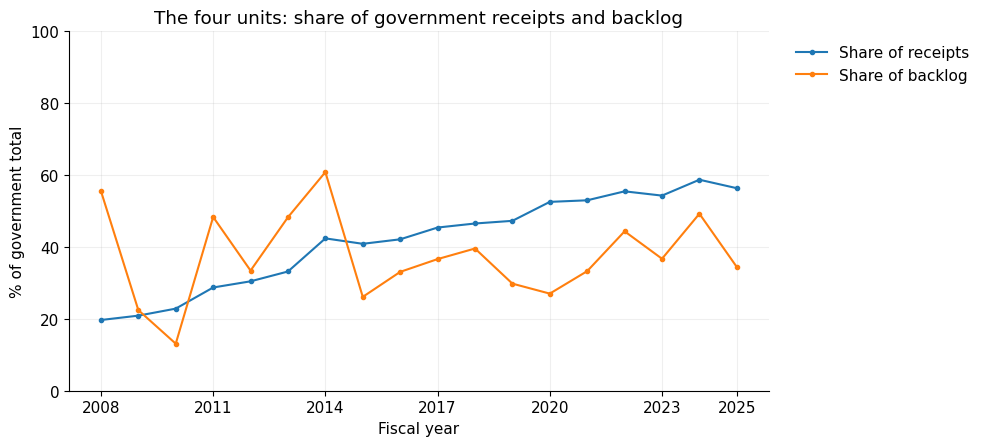

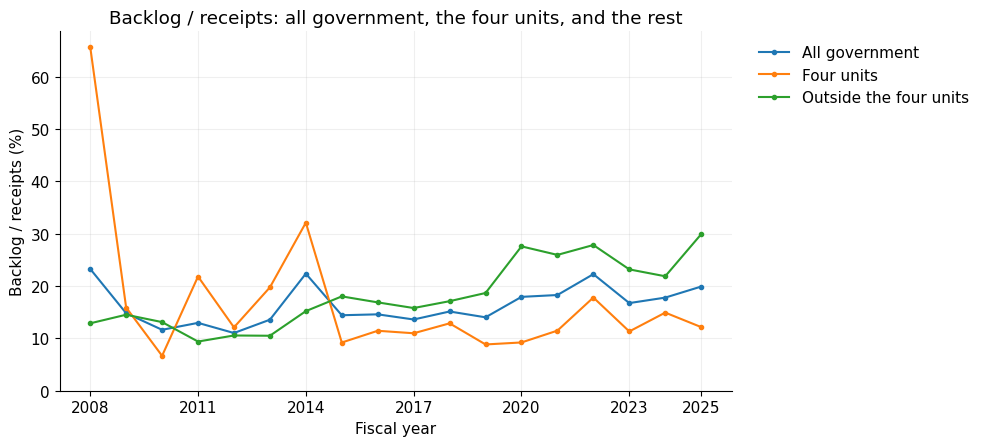

The four units (%)                  Backlog / receipts (%)             \
      Share of receipts Share of backlog         All government Four units   
2008               19.7             55.6                   23.3       65.7   
2009               20.9             22.4                   14.8       15.9   
2010               22.8             13.1                   11.6        6.7   
2011               28.7             48.3                   13.0       21.8   
2012               30.4             33.4                   11.0       12.1   
2013               33.2             48.3                   13.6       19.7   
2014               42.4             60.8                   22.4       32.1   
2015               40.9             26.1                   14.4        9.2   
2016               42.1             33.1                   14.6       11.5   
2017               45.4             36.6                   13.6       11.0   
2018               46.5             39.6                   15.1       12.9   
2019               47.3             29.8                   14.0        8.8   
2020               52.5             27.0                   17.9        9.2   
2021               53.0             33.3                   18.3       11.5   
2022               55.5             44.4                   22.3       17.8   
2023               54.3             36.7                   16.7       11.3   
2024               58.7             49.3                   17.8       14.9   
2025               56.4             34.4                   19.9       12.2   

                             
     Outside the four units  
2008                   12.9  
2009                   14.5  
2010                   13.1  
2011                    9.4  
2012                   10.6  
2013                   10.5  
2014                   15.2  
2015                   18.0  
2016                   16.9  
2017                   15.8  
2018                   17.1  
2019                   18.7  
2020                   27.6  
2021                   25.9  
2022                   27.8  
2023                   23.2  
2024                   21.9  
2025                   29.9

,FY2014–19 average (%),FY2020–25 average (%),Change (pp)
All government,15.7,18.8,3.1
Four units,14.2,12.8,-1.4
Outside the four units,16.9,26.0,9.1


,pp
The rest: own change × the rest's average share,4.55
The four units: own change × their average share,-0.39
The four units' growing share of receipts (total minus the other two),-0.92
"Total change, six-year totals",3.24


In [2]:
# Section 2: the four units versus the rest
shares=pd.DataFrame({label:{y:100*tot(G,c,y,imm)/tot(G,c,y) for y in YR} for label,c in [('Share of receipts',REC),('Share of backlog',BLR)]})
chart(shares,'The four units: share of government receipts and backlog','% of government total',ylim=(0,100))
scopes=pd.DataFrame({'All government':series([BLR],[REC]),'Four units':series([BLR],[REC],imm),'Outside the four units':series([BLR],[REC],ni)})
chart(scopes,'Backlog / receipts: all government, the four units, and the rest','Backlog / receipts (%)',ylim=(0,None))
display(pd.concat({'The four units (%)':shares,'Backlog / receipts (%)':scopes},axis=1).round(1))
assert shares['Share of receipts'].loc[[2008,2019,2025]].round(1).tolist()==[19.7,47.3,56.4]
means=pd.DataFrame({'FY2014–19 average (%)':scopes.loc[2014:2019].mean(),'FY2020–25 average (%)':scopes.loc[2020:2025].mean()})
means['Change (pp)']=means.iloc[:,1]-means.iloc[:,0]
display(means.round(1))
assert means.round(1).values.tolist()==[[15.7,18.8,3.1],[14.2,12.8,-1.4],[16.9,26.0,9.1]]

# Why the government-wide ratio rose so little: six-year totals, all = w x four units + (1 - w) x rest, w = the four units' share of receipts
W={p:sum(tot(G,REC,y,imm) for y in range(a,b+1))/sum(tot(G,REC,y) for y in range(a,b+1)) for p,(a,b) in {'0':(2014,2019),'1':(2020,2025)}.items()}
r4={p:pooled(imm,a,b)/100 for p,(a,b) in {'0':(2014,2019),'1':(2020,2025)}.items()}
ro={p:pooled(ni,a,b)/100 for p,(a,b) in {'0':(2014,2019),'1':(2020,2025)}.items()}
total=round(pooled(lambda r:True,2020,2025)-pooled(lambda r:True,2014,2019),2)
rest_own=round(100*(ro['1']-ro['0'])*((1-W['0'])+(1-W['1']))/2,2)
four_own=round(100*(r4['1']-r4['0'])*(W['0']+W['1'])/2,2)
split=pd.Series({"The rest: own change × the rest's average share":rest_own,"The four units: own change × their average share":four_own,
                 "The four units' growing share of receipts (total minus the other two)":round(total-rest_own-four_own,2),'Total change, six-year totals':total})
display(split.to_frame('pp'))
assert split.tolist()==[4.55,-0.39,-0.92,3.24]
assert [round(100*W['0'],1),round(100*W['1'],1),round(100*(ro['1']-ro['0']),2),round(100*((1-W['0'])+(1-W['1']))/2,1)]==[44.3,55.6,9.08,50.1]

**Section 2:**
- The four units' share of government receipts rose from 19.7% in FY2008 to 47.3% in FY2019 and 56.4% in FY2025.
- Six-year averages of the yearly ratio: all government 15.7% to 18.8% (+3.1 points); the four units 14.2% to 12.8% (−1.4); outside the four units 16.9% to 26.0% (+9.1).
- **Why the government-wide ratio rose only about 3 points** (second table; six-year totals of backlog and receipts are divided, so the figures differ slightly from the averages):
  - outside the four units the ratio itself rose 9.08 points, but those units hold only 50.1% of receipts on average across the two periods, so they add +4.55;
  - the four units' own ratio fell slightly, −0.39;
  - their share of receipts rose from 44.3% to 55.6%, pulling the total down by 0.92 (this part is the total minus the other two);
  - total +3.24.

Units outside the four hold only about half of receipts, so their rise shows up at about half its size in the government-wide figure. This is the same mechanism as DHS in Storyline 1, Section 2. From here on, look outside the four units.

## 3. Outside the four units: a rise in stages

First the full series and period averages outside the four units, then two checks: some agencies are missing in FY2008–09, and DOS added the most backlog. Does the climb survive without DOS?

,Average of yearly backlog / receipts (%)
FY2008–10,13.5
FY2011–13,10.1
FY2014–19,16.9
FY2020–25,26.0


Reporting units: changes only where both year labels exist


,FY2019,FY2024,Change
Unit,,,
DOS/DOS - Main,"11,086","21,473","10,387"
DOJ/BOP,"2,341","5,679","3,338"
DHS/PRIV,"1,379","4,074","2,695"
CIA/Agency Overall,"2,384","4,879","2,495"
DHS/USCG,"1,379","3,597","2,218"
DoD/DA,"1,016","3,150","2,134"
DoD/DAF,"1,444","3,366","1,922"
DOT/FMCSA,"1,423","3,340","1,917"
NARA/Agency Overall,"3,359","5,107","1,748"


90 reporting labels occur in only one of the two years; absent rows are not zeros (example: ED below).


,FY2019,FY2024,Change
Unit,,,
ED/Agency Overall,–,"2,485",–


Agency totals (DHS and DOJ exclude the four units)


,FY2019,FY2024,Change
Unit,,,
DOS,"11,106","21,615","10,509"
DoD,"13,198","21,436","8,238"
DHS (other components),"4,722","11,415","6,693"
HHS,"7,764","12,685","4,921"
DOT,"3,578","8,048","4,470"
DOJ (excl. EOIR),"16,403","20,046","3,643"
CIA,"2,384","4,879","2,495"
NARA,"3,359","5,107","1,748"
ED,914,"2,485","1,571"


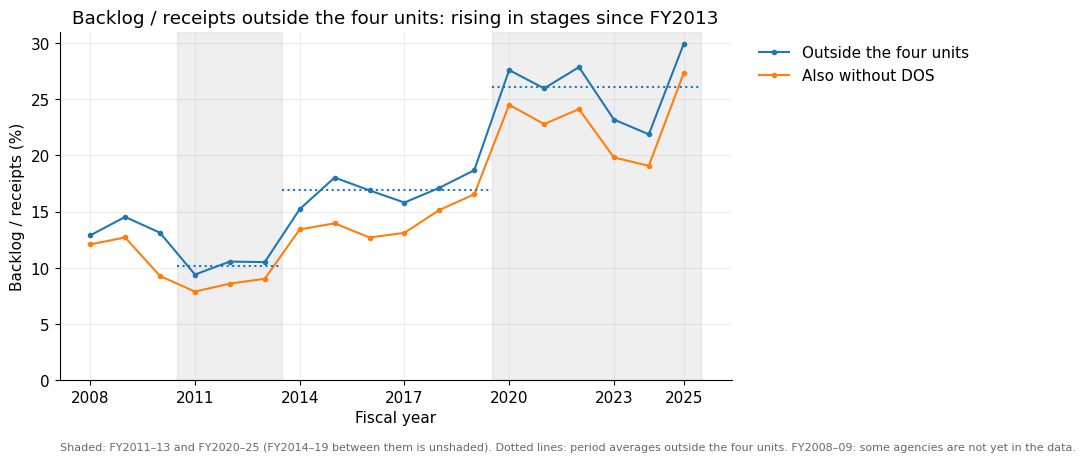

In [3]:
# Section 3: outside the four units, the whole series
out=series([BLR],[REC],ni)
check(out,[12.9,14.5,13.1,9.4,10.6,10.5,15.2,18.0,16.9,15.8,17.1,18.7,27.6,25.9,27.8,23.2,21.9,29.9])
stages=pd.Series({'FY2008–10':out.loc[2008:2010].mean(),'FY2011–13':out.loc[2011:2013].mean(),'FY2014–19':out.loc[2014:2019].mean(),'FY2020–25':out.loc[2020:2025].mean()})
display(stages.round(1).to_frame('Average of yearly backlog / receipts (%)'))
assert stages.round(1).tolist()==[13.5,10.1,16.9,26.0]
assert out.diff().round(1).sort_values(ascending=False).head(3).to_dict()=={2020:8.9,2025:8.0,2014:4.7}
assert round(out[2019]-out[2013],1)==8.2
lo=removals([BLR],[REC],ni)
assert round((lo.loc[2019]-lo.loc[2013]).drop('Baseline').min(),1)==6.5
# FY2008-09 coverage: agencies with receipts in FY2010 but none in FY2008
rec_ag={y:{k for k,v in bykey(y,REC,ni,AGK).items() if v} for y in (2008,2010)}
late=rec_ag[2010]-rec_ag[2008]; in_late=lambda r:ni(r) and AGK(r) in late
assert len(late)==27 and [round(100*tot(G,c,2010,in_late)/tot(G,c,2010,ni),1) for c in (REC,BLR)]==[12.1,3.9]
no_rows08={k for k in late if not any(r['Fiscal Year']=='2008' and AGK(r)==k for r in G)}
assert len(no_rows08)==26 and late-no_rows08=={'FFIEC'} and 'SIGAR' in late   # FFIEC has an FY2008 row with zero receipts
assert sum(sum(num(r[c]) or 0 for c in c02) for r in G if r['Fiscal Year']=='2010' and AGK(r)=='SIGAR')==0   # why Storyline 1 (dispositions) counts 26
assert [y for y,v in out.diff().loc[2014:2025].items() if v<0]==[2016,2017,2021,2023,2024]

# Which agencies added the most backlog FY2019 -> FY2024, and does the climb survive without DOS?
def growth_table(level):
    totals=table([BLR],ni)[level]
    units={k for y,k in totals if y in [2019,2024]}
    frame=pd.DataFrame([(k,totals.get((2019,k),float('nan')),totals.get((2024,k),float('nan'))) for k in units],columns=['Unit','FY2019','FY2024']).set_index('Unit')
    frame['Change']=frame['FY2024']-frame['FY2019']
    return frame.sort_values('Change',ascending=False)
component_changes=growth_table('co'); agency_changes=growth_table('ag')
print('Reporting units: changes only where both year labels exist')
display(component_changes.dropna().head(10).style.format('{:,.0f}',na_rep='–'))
assert component_changes.loc['DOS/DOS - Main',['FY2019','FY2024','Change']].tolist()==[11086,21473,10387]
unmatched=component_changes.loc[component_changes[['FY2019','FY2024']].isna().any(axis=1)]
assert len(unmatched)==90
print(f'{len(unmatched)} reporting labels occur in only one of the two years; absent rows are not zeros (example: ED below).')
display(unmatched.loc[['ED/Agency Overall']].style.format('{:,.0f}',na_rep='–'))
assert agency_changes.loc['ED',['FY2019','FY2024','Change']].tolist()==[914,2485,1571]
assert agency_changes.loc[['DOS','DoD','DHS','HHS'],'Change'].tolist()==[10509,8238,6693,4921]
print('Agency totals (DHS and DOJ exclude the four units)')
display(agency_changes.rename(index={'DHS':'DHS (other components)','DOJ':'DOJ (excl. EOIR)'}).head(10).style.format('{:,.0f}',na_rep='–'))
result=pd.DataFrame({'Outside the four units':out,'Also without DOS':series([BLR],[REC],lambda r:ni(r) and AGK(r)!='DOS')})
check(result.iloc[:,1],[12.1,12.7,9.3,7.9,8.6,9.0,13.4,13.9,12.7,13.1,15.1,16.5,24.5,22.8,24.1,19.8,19.1,27.3])
ax=result.plot(marker='o',markersize=3,figsize=(10,4.8))
for (a,b),m in [((2011,2013),stages['FY2011–13']),((2014,2019),stages['FY2014–19']),((2020,2025),stages['FY2020–25'])]:
    if a!=2014: ax.axvspan(a-0.5,b+0.5,color='grey',alpha=0.12)
    ax.hlines(m,a-0.5,b+0.5,colors='C0',linestyles=':',linewidth=1.5)
ax.set(title='Backlog / receipts outside the four units: rising in stages since FY2013',xlabel='Fiscal year',ylabel='Backlog / receipts (%)',ylim=(0,None))
ax.set_xticks([2008,2011,2014,2017,2020,2023,2025]); ax.grid(alpha=.2); ax.legend(bbox_to_anchor=(1.02,1),loc='upper left',frameon=False)
ax.text(0,-0.2,'Shaded: FY2011–13 and FY2020–25 (FY2014–19 between them is unshaded). Dotted lines: period averages outside the four units. FY2008–09: some agencies are not yet in the data.',transform=ax.transAxes,fontsize=8,color='dimgray')
plt.tight_layout(); plt.show()

**Section 3:**
- Outside the four units, backlog ÷ receipts averaged 13.5% in FY2008–10, fell to 10.1% in FY2011–13, then 16.9% in FY2014–19 and 26.0% in FY2020–25.
- **It has climbed in stages since FY2013, with five down years out of twelve** (FY2016, FY2017, FY2021, FY2023 and FY2024). From FY2013 to FY2019 it already rose 8.2 points (10.5% to 18.7%), and at least 6.5 points after removing any single unit. The largest single-year rises are FY2020 (+8.9), FY2025 (+8.0) and FY2014 (+4.7). FY2020 is the largest but not the only one, so it is not presented as a break; on the chart, FY2011–13 and FY2020–25 are shaded, FY2014–19 between them is not, and dotted lines mark each period's average.
- **Some agencies are missing in FY2008–09:** 27 agencies have receipts in FY2010 but none in FY2008 (26 have no FY2008 rows at all; FFIEC has a row with zero receipts); in FY2010 they account for 12.1% of receipts and 3.9% of backlog outside the four units. Storyline 1, counting dispositions, finds 26; the difference is SIGAR, which had receipts but no dispositions in FY2010. The rise is therefore safer to state from FY2011–13.
- **DOS:** DOS added the most backlog from FY2019 to FY2024 (+10,509), followed by DoD (+8,238), DHS's other components (+6,693) and HHS (+4,921). Without all of DOS, the ratio still rises from 16.5% in FY2019 to 24.5% in FY2020 and stays higher, so the pattern is not DOS's alone.
- 90 reporting labels appear in only one of the two years and are not filled with zeros. For example, ED reports by component in FY2019 and as a whole agency in FY2024; its agency total goes from 914 to 2,485 (+1,571), not from zero.

## 4. Is it broad?

Is the rise outside the four units a matter of most agencies' own ratios rising, or of a few agencies' weights changing? The method follows Storyline 1, Section 6. Only agencies with data in every year from FY2014 to FY2025 are used (96, covering 99.8% of FY2020–25 receipts outside the four units); for each, six-year totals of backlog and receipts are divided for FY2014–19 and FY2020–25 and the two periods compared.

,Agencies compared,Ratio higher in FY2020–25,Share of agencies (%),Their share of FY2020–25 receipts (%)
Minimum receipts in each six-year window,,,,
0,96,69,72,66
600,56,42,75,66
6000,28,24,86,66
60000,14,11,79,62


,FY2014–19 (%),FY2020–25 (%),Change (pp)
DHS (other components),20.1,18.0,-2.2
VA,9.7,3.2,-6.5
DoD,18.2,34.4,16.2
HHS,15.9,27.7,11.8
DOJ (excl. EOIR),29.8,49.9,20.1
NARA,10.1,21.5,11.4
USDA,7.5,11.3,3.8
DOT,19.9,37.6,17.7
DOS,90.4,116.2,25.8
EEOC,5.5,1.7,-3.8


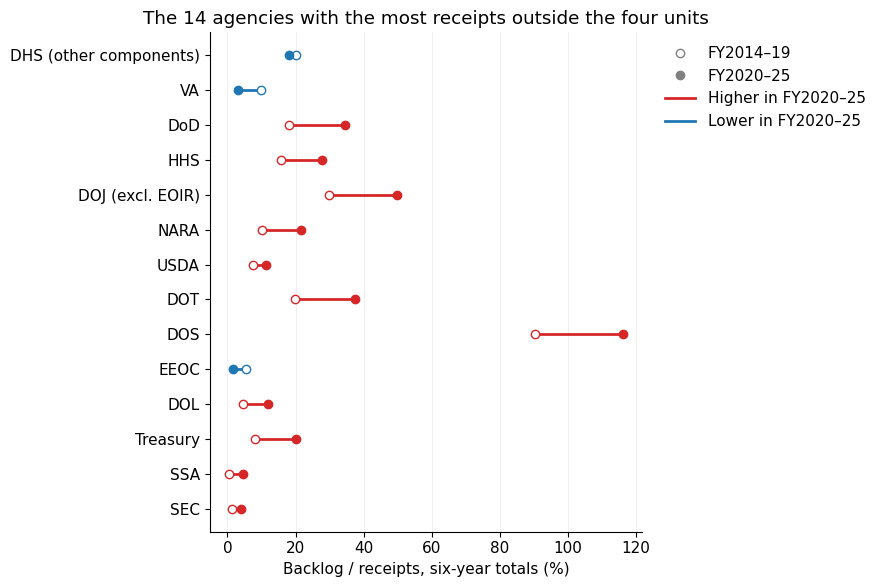

,FY2014–19 (%),FY2020–25 (%),Receipts FY2014–19,Receipts FY2020–25
DHS PRIV and CISA,10.0,13.9,154040,495361
DHS other components except PRIV and CISA,54.5,59.7,45514,48712
VBA,36.9,3.1,24360,267785
VA except VBA,4.9,3.4,137891,111301


,pp,Remainder (weights),Total
Within (start weights),10.31,-1.28,9.03
Within (end weights),8.10,0.93,9.03
Within (mean weights),9.20,-0.17,9.03


In [4]:
# Section 4: is the rise broad? Agencies with data in every year FY2014-25; six-year totals divided, FY2014-19 vs FY2020-25
def pooled_by_agency(a,b):
    bl,rc,n=defaultdict(float),defaultdict(float),defaultdict(int)
    for y in range(a,b+1):
        r_y=bykey(y,REC,ni,AGK); b_y=bykey(y,BLR,ni,AGK)
        for k,v in r_y.items(): rc[k]+=v; bl[k]+=b_y.get(k,0); n[k]+=1
    return {k:(100*bl[k]/rc[k],rc[k]) for k in rc if n[k]==b-a+1 and rc[k]>0}
p0,p1=pooled_by_agency(2014,2019),pooled_by_agency(2020,2025)
rows=[]
for th in (0,600,6000,60000):
    ks=[k for k in p0 if k in p1 and p0[k][1]>=th and p1[k][1]>=th]; up=[k for k in ks if p1[k][0]>p0[k][0]]
    rows.append({'Minimum receipts in each six-year window':th,'Agencies compared':len(ks),'Ratio higher in FY2020–25':len(up),
                 'Share of agencies (%)':100*len(up)/len(ks),'Their share of FY2020–25 receipts (%)':100*sum(p1[k][1] for k in up)/sum(p1[k][1] for k in ks)})
breadth=pd.DataFrame(rows).set_index('Minimum receipts in each six-year window')
display(breadth.round(0).astype(int))
assert breadth[['Agencies compared','Ratio higher in FY2020–25']].values.tolist()==[[96,69],[56,42],[28,24],[14,11]]
assert breadth['Share of agencies (%)'].round(0).tolist()==[72,75,86,79] and breadth['Their share of FY2020–25 receipts (%)'].round(0).tolist()==[66,66,66,62]
allrec=sum(tot(G,REC,y,ni) for y in range(2020,2026)); assert round(100*sum(p1[k][1] for k in p0 if k in p1)/allrec,1)==99.8

top=sorted([k for k in p0 if k in p1],key=lambda k:-p1[k][1])[:14]
top14=pd.DataFrame({'FY2014–19 (%)':{k:p0[k][0] for k in top},'FY2020–25 (%)':{k:p1[k][0] for k in top}}).loc[top]
top14['Change (pp)']=top14.iloc[:,1]-top14.iloc[:,0]
display(top14.rename(index={'DHS':'DHS (other components)','DOJ':'DOJ (excl. EOIR)'}).round(1))
fig,ax=plt.subplots(figsize=(9,6)); names={'DHS':'DHS (other components)','DOJ':'DOJ (excl. EOIR)'}
for i,k in enumerate(top[::-1]):
    v0,v1=top14.loc[k,'FY2014–19 (%)'],top14.loc[k,'FY2020–25 (%)']; colr='#d62728' if v1>v0 else '#1f77b4'
    ax.plot([v0,v1],[i,i],color=colr,lw=2); ax.scatter([v0],[i],color='white',edgecolor=colr,zorder=3,s=36); ax.scatter([v1],[i],color=colr,zorder=3,s=36)
ax.set_yticks(range(len(top))); ax.set_yticklabels([names.get(k,k) for k in top[::-1]])
ax.set(title='The 14 agencies with the most receipts outside the four units',xlabel='Backlog / receipts, six-year totals (%)'); ax.grid(axis='x',alpha=.2)
ax.legend(handles=[Line2D([],[],marker='o',color='grey',markerfacecolor='white',ls='',label='FY2014–19'),Line2D([],[],marker='o',color='grey',ls='',label='FY2020–25'),
                   Line2D([],[],color='#d62728',lw=2,label='Higher in FY2020–25'),Line2D([],[],color='#1f77b4',lw=2,label='Lower in FY2020–25')],bbox_to_anchor=(1.02,1),loc='upper left',frameon=False)
plt.tight_layout(); plt.show()
assert {k for k in top if top14.loc[k,'Change (pp)']<0}=={'DHS','VA','EEOC'}
t14=top14.round(1)
assert t14.loc[['DHS','VA','EEOC'],'FY2014–19 (%)'].tolist()==[20.1,9.7,5.5] and t14.loc[['DHS','VA','EEOC'],'FY2020–25 (%)'].tolist()==[18.0,3.2,1.7]
assert t14.loc[['DoD','DOJ','HHS','DOT','DOS','Treasury'],'FY2014–19 (%)'].tolist()==[18.2,29.8,15.9,19.9,90.4,8.2]
assert t14.loc[['DoD','DOJ','HHS','DOT','DOS','Treasury'],'FY2020–25 (%)'].tolist()==[34.4,49.9,27.7,37.6,116.2,20.1]
assert [round(top14.loc[['DoD','DOJ','HHS','DOT','DOS','Treasury'],'Change (pp)'].min(),1),round(top14.loc[['DoD','DOJ','HHS','DOT','DOS','Treasury'],'Change (pp)'].max(),1)]==[11.8,25.8]
# The three large agencies whose ratio fell
sub={'DHS PRIV and CISA':isPC,'DHS other components except PRIV and CISA':lambda r:ni(r) and AGK(r)=='DHS' and not isPC(r),'VBA':vba,'VA except VBA':lambda r:AGK(r)=='VA' and not vba(r)}
six=lambda f,a:sum(tot(G,REC,y,f) for y in range(a,a+6))
falls=pd.DataFrame({k:{'FY2014–19 (%)':pooled(f,2014,2019),'FY2020–25 (%)':pooled(f,2020,2025),'Receipts FY2014–19':six(f,2014),'Receipts FY2020–25':six(f,2020)} for k,f in sub.items()}).T
display(falls.round(1).astype({'Receipts FY2014–19':int,'Receipts FY2020–25':int}))
assert falls.iloc[:,:2].round(1).values.tolist()==[[10.0,13.9],[54.5,59.7],[36.9,3.1],[4.9,3.4]]
assert falls.iloc[:2,2:].astype(int).values.tolist()==[[154040,495361],[45514,48712]]

# Agency's own change versus weights (as in Storyline 1, Section 6); the remainder is the total minus the within part, from the two-decimal values
ks=[k for k in p0 if k in p1]; R0=sum(p0[k][1] for k in ks); R1=sum(p1[k][1] for k in ks)
total=round(sum(p1[k][0]*p1[k][1] for k in ks)/R1-sum(p0[k][0]*p0[k][1] for k in ks)/R0,2)
w_start=sum(p0[k][1]/R0*(p1[k][0]-p0[k][0]) for k in ks); w_end=sum(p1[k][1]/R1*(p1[k][0]-p0[k][0]) for k in ks)
within=pd.DataFrame({'Within (start weights)':round(w_start,2),'Within (end weights)':round(w_end,2),'Within (mean weights)':round((w_start+w_end)/2,2)},index=['pp']).T
within['Remainder (weights)']=(total-within['pp']).round(2); within['Total']=total
display(within)
assert within['pp'].tolist()==[10.31,8.10,9.20] and within['Remainder (weights)'].tolist()==[-1.28,0.93,-0.17] and total==9.03

**Section 4:**
- **Most agencies rose:** 69 of 96 (72%); 42 of the 56 with at least 600 receipts in each six-year window, 24 of the 28 with at least 6,000 (86%), and 11 of the 14 with at least 60,000. By FY2020–25 receipts the share is 62%–66%.
- **The receipts-weighted share is lower because three large agencies fell, two of them units whose receipts swing sharply (third table):**
  - DHS's other components fell from 20.1% to 18.0%, a mix effect: PRIV and CISA (one stream of requests, reported under CISA through FY2018 and under PRIV from FY2019; Storyline 0, Section 3) rose from 10.0% to 13.9%, and DHS's other components except these two rose from 54.5% to 59.7%; the combined ratio fell because low-ratio PRIV and CISA grew from 154,040 to 495,361 six-year receipts.
  - VA fell from 9.7% to 3.2%, mainly at VBA (36.9% to 3.1%); the rest of VA went from 4.9% to 3.4%.
  - EEOC fell from 5.5% to 1.7%.
- **Chart:** the 14 agencies with the most receipts; hollow dots are FY2014–19 and filled dots FY2020–25; red lines rose (11), blue lines fell (3: DHS's other components, VA and EEOC).
- **The large traditional departments all rose:** DoD 18.2% to 34.4%, DOJ (excluding EOIR) 29.8% to 49.9%, HHS 15.9% to 27.7%, DOT 19.9% to 37.6%, DOS 90.4% to 116.2%, and Treasury 8.2% to 20.1%, rises of 11.8 to 25.8 points. DOS's backlog now exceeds a year of its receipts.
- **Mainly within agencies:** split by agency, of the +9.03-point total the within-agency change is +10.31 with start weights, +8.10 with end weights and +9.20 on average; the remainder (weights) is between −1.28 and +0.93 (from the two-decimal values shown).

## 5. Where do the two bumps come from?

The series has two visible bumps: the FY2020 jump and the FY2023–24 dip. The annual reports do not show causes, but they do show whether the numerator or the denominator moved, and at which units.

,Received,Backlogged
2019,452915,84549
2020,375203,103458


,Change (%)
Received,-17.2
Backlogged,22.4


,"Change in receipts, FY2019 → FY2020"
Outside the four units,-77712
NARA,-41728
DHS PRIV,-18903
All other units,-17081


,"Change in backlog, FY2019 → FY2020"
DHS (other components),4247
DoD,2802
DOS,2692
DOJ (excl. EOIR),2607
SSA,1622
HHS,1053


2021   2022   2023    2024    2025
VBA      Receipts  11653   5529  61658   84266  100897
         Backlog    1467     74    219    1121    3374
DHS PRIV Receipts  53432  74698  86174  106117  147664
         Backlog     450    600   8046    4074   48433

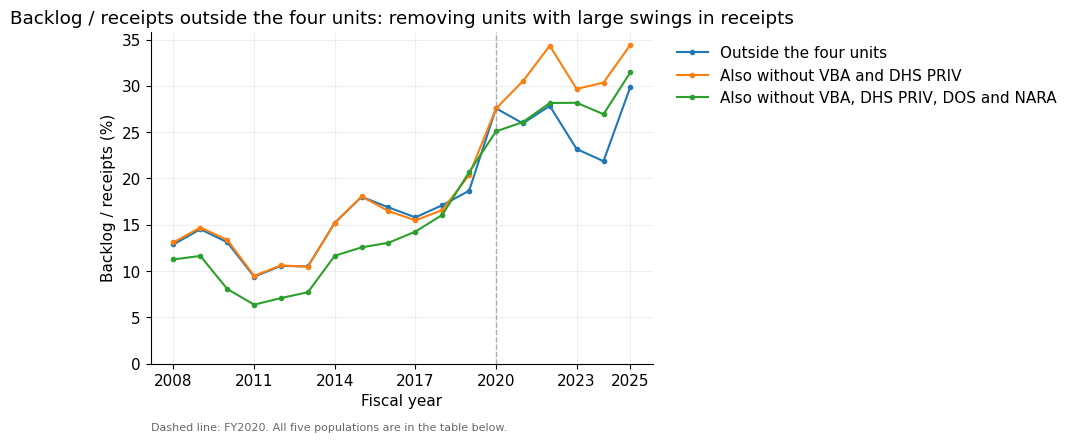

,2017,2018,2019,2020,2021,2022,2023,2024,2025,FY2020–25 avg minus FY2014–19 avg,Lowest FY2020–25 minus highest FY2008–19
Outside the four units,15.8,17.1,18.7,27.6,25.9,27.8,23.2,21.9,29.9,9.1,3.2
Also without VBA,15.5,16.6,18.7,27.3,26.4,28.2,26.1,25.1,34.1,11.1,6.4
Also without DHS PRIV,15.7,17.0,20.3,27.8,29.9,33.8,25.8,25.6,29.2,11.5,5.3
Also without VBA and DHS PRIV,15.5,16.6,20.4,27.6,30.5,34.3,29.7,30.3,34.4,14.1,7.2
"Also without VBA, DHS PRIV, DOS and NARA",14.3,16.1,20.7,25.1,26.1,28.1,28.2,26.9,31.5,12.9,4.4


Also without CISA: average increase 13.9 pp; lowest FY2020-25 minus highest FY2008-19 7.2 pp; lowest FY2020-25 27.5%
Without VBA and DHS PRIV, 588 single-unit removals: smallest average increase 13.0 pp (removing DOJ); smallest separation 5.2 pp (removing NARA); smallest increase without FY2025 12.1 pp


In [5]:
# Section 5a: FY2019 -> FY2020, numerator and denominator
t=pd.DataFrame({y:{'Received':tot(G,REC,y,ni),'Backlogged':tot(G,BLR,y,ni)} for y in [2019,2020]}).T
assert t.values.tolist()==[[452915,84549],[375203,103458]]
display(t.astype(int)); pct=((t.loc[2020]/t.loc[2019]-1)*100).round(1); display(pct.to_frame('Change (%)'))
assert pct.tolist()==[-17.2,22.4]
# Receipts: which units
d=lambda c,f:tot(G,c,2020,f)-tot(G,c,2019,f)
rec_drop=pd.Series({'Outside the four units':d(REC,ni),'NARA':d(REC,isNARA),'DHS PRIV':d(REC,isPRIV)}); rec_drop['All other units']=rec_drop.iloc[0]-rec_drop.iloc[1]-rec_drop.iloc[2]
display(rec_drop.astype(int).to_frame('Change in receipts, FY2019 → FY2020'))
assert rec_drop.astype(int).tolist()==[-77712,-41728,-18903,-17081] and round(100*(rec_drop['NARA']+rec_drop['DHS PRIV'])/rec_drop.iloc[0])==78
nara_rec=[int(tot(G,REC,y,isNARA)) for y in range(2019,2024)]; assert nara_rec==[67466,25738,7725,14975,62505]
assert [int(tot(G,REC,y,isPRIV)) for y in (2018,2019,2020)]==[1448,43024,24121]
assert [int(tot(G,REC,y,isCISA)) for y in (2018,2019)]==[37516,353] and [int(tot(G,REC,y,isPC)) for y in (2019,2020)]==[43377,24298]   # FY2019: transfer; FY2020: a real fall
no_nara=lambda r:ni(r) and not isNARA(r)
t2=pd.DataFrame({y:{'Received':tot(G,REC,y,no_nara),'Backlogged':tot(G,BLR,y,no_nara)} for y in (2019,2020)}).T
assert t2.astype(int).values.tolist()==[[385449,81190],[349465,99947]] and ((t2.loc[2020]/t2.loc[2019]-1)*100).round(1).tolist()==[-9.3,23.1]
# Backlog: which agencies
b19,b20=bykey(2019,BLR,ni,AGK),bykey(2020,BLR,ni,AGK)
bl_up=pd.Series({k:b20.get(k,0)-b19.get(k,0) for k in set(b19)|set(b20)}).sort_values(ascending=False)
display(bl_up.head(6).astype(int).rename(index={'DHS':'DHS (other components)','DOJ':'DOJ (excl. EOIR)'}).to_frame('Change in backlog, FY2019 → FY2020'))
assert int(bl_up.sum())==18909 and bl_up.head(6).astype(int).to_dict()=={'DHS':4247,'DoD':2802,'DOS':2692,'DOJ':2607,'SSA':1622,'HHS':1053}

# Section 5b: FY2023-24 dip. Two units with large receipts and little backlog
vp=pd.DataFrame({(u,m):{y:tot(G,c,y,f) for y in range(2021,2026)} for u,f in [('VBA',vba),('DHS PRIV',isPRIV)] for m,c in [('Receipts',REC),('Backlog',BLR)]}).T
display(vp.astype(int))
assert vp.astype(int).values.tolist()==[[11653,5529,61658,84266,100897],[1467,74,219,1121,3374],[53432,74698,86174,106117,147664],[450,600,8046,4074,48433]]
pops={'Outside the four units':ni,'Also without VBA':lambda r:ni(r) and not vba(r),'Also without DHS PRIV':lambda r:ni(r) and not isPRIV(r),
      'Also without VBA and DHS PRIV':lambda r:ni(r) and not vba(r) and not isPRIV(r),'Also without VBA, DHS PRIV, DOS and NARA':lambda r:ni(r) and not vba(r) and not isPRIV(r) and AGK(r) not in ('DOS','NARA')}
alt=pd.DataFrame({k:series([BLR],[REC],f) for k,f in pops.items()})
chart(alt[['Outside the four units','Also without VBA and DHS PRIV','Also without VBA, DHS PRIV, DOS and NARA']],'Backlog / receipts outside the four units: removing units with large swings in receipts','Backlog / receipts (%)',ylim=(0,None),vline=2020,note='Dashed line: FY2020. All five populations are in the table below.')
alt_tab=alt.loc[2017:2025].T
alt_tab['FY2020–25 avg minus FY2014–19 avg']=alt.loc[2020:2025].mean()-alt.loc[2014:2019].mean()
alt_tab['Lowest FY2020–25 minus highest FY2008–19']=alt.loc[2020:2025].min()-alt.loc[2008:2019].max()
display(alt_tab.round(1))
assert alt_tab.iloc[:,-2].round(1).tolist()==[9.1,11.1,11.5,14.1,12.9] and alt_tab.iloc[:,-1].round(1).tolist()==[3.2,6.4,5.3,7.2,4.4]
assert round(alt.loc[2020:2025,'Also without VBA and DHS PRIV'].min(),1)==27.6
alt_c=series([BLR],[REC],lambda r:ni(r) and not vba(r) and not isPC(r))      # also without CISA, which reported PRIV's requests through FY2018
assert [round(alt_c.loc[2020:2025].mean()-alt_c.loc[2014:2019].mean(),1),round(alt_c.loc[2020:2025].min()-alt_c.loc[2008:2019].max(),1),round(alt_c.loc[2020:2025].min(),1)]==[13.9,7.2,27.5]
print(f'Also without CISA: average increase {alt_c.loc[2020:2025].mean()-alt_c.loc[2014:2019].mean():.1f} pp; lowest FY2020-25 minus highest FY2008-19 {alt_c.loc[2020:2025].min()-alt_c.loc[2008:2019].max():.1f} pp; lowest FY2020-25 {alt_c.loc[2020:2025].min():.1f}%')
assert alt.loc[2017:2020,'Also without VBA, DHS PRIV, DOS and NARA'].round(1).tolist()==[14.3,16.1,20.7,25.1]
lo_vp=removals([BLR],[REC],pops['Also without VBA and DHS PRIV'])
g=(lo_vp.loc[2020:2025].mean()-lo_vp.loc[2014:2019].mean()).drop('Baseline'); sp=(lo_vp.loc[2020:2025].min()-lo_vp.loc[2008:2019].max()).drop('Baseline')
g24=(lo_vp.loc[2020:2024].mean()-lo_vp.loc[2014:2019].mean()).drop('Baseline')
assert lo_vp.shape[1]-1==588 and round(g.min(),1)==13.0 and g.idxmin()=="('ag', 'DOJ')" and round(sp.min(),1)==5.2 and sp.idxmin()=="('ag', 'NARA')" and round(g24.min(),1)==12.1
print(f'Without VBA and DHS PRIV, {lo_vp.shape[1]-1} single-unit removals: smallest average increase {g.min():.1f} pp (removing DOJ); smallest separation {sp.min():.1f} pp (removing NARA); smallest increase without FY2025 {g24.min():.1f} pp')

**The FY2020 jump:**
- Outside the four units, receipts fell from 452,915 in FY2019 to 375,203 in FY2020 (−17.2%) while backlog rose from 84,549 to 103,458 (+22.4%); both push the ratio up.
- **The fall in receipts is concentrated at two units:** of the 77,712 drop, NARA accounts for 41,728 and DHS PRIV for 18,903, 78% together; all other units −17,081. Both units' receipts swing sharply anyway: NARA received 67,466, 25,738, 7,725, 14,975 and 62,505 in FY2019–23; PRIV received 1,448 in FY2018, 43,024 in FY2019 and 24,121 in FY2020. The FY2019 rise is a transfer from CISA, whose receipts fell from 37,516 to 353 that year (Storyline 0, Section 3); the FY2020 fall is real, with the two together falling from 43,377 to 24,298.
- **The rise in backlog is spread out:** of +18,909, DHS's other components +4,247, DoD +2,802, DOS +2,692, DOJ +2,607, SSA +1,622, HHS +1,053.
- Without NARA, receipts fall only 9.3% (385,449 to 349,465) and backlog rises 23.1% (81,190 to 99,947).

**The FY2023–24 dip:** VBA and PRIV received many more requests while carrying little backlog, which enlarged the denominator. VBA's receipts rose from 5,529 in FY2022 to 100,897 in FY2025, with backlog of at most 3,374 in FY2021–25; PRIV's receipts rose from 53,432 in FY2021 to 147,664 in FY2025, with backlog of at most 8,046 in FY2021–24 (48,433 in FY2025; see Section 8).
- Without these two units, the ratio is 27.6% or higher in every year from FY2020, with no dip; the FY2020–25 average is 14.1 points above FY2014–19, and the lowest FY2020–25 value is 7.2 points above the highest FY2008–19 value (second comparison table).
- PRIV's requests were reported under CISA through FY2018; also removing CISA, the average increase is 13.9 points, the lowest-minus-highest margin is still 7.2 points, and every year from FY2020 is still 27.5% or higher.
- Within that population, after removing any single unit (588 removals), the average increase is at least 13.0 points (removing all of DOJ), the lowest-minus-highest margin at least 5.2 points (removing NARA), and the increase without FY2025 at least 12.1 points.
- Removing DOS and NARA as well, FY2017–20 reads 14.3%, 16.1%, 20.7% and 25.1%: the FY2020 jump shrinks and the series looks more like a steady climb.
- **This is a sensitivity check only; the main population does not change.** Choosing units to remove after seeing the results would be choosing data for the conclusion. The check shows two things: without the two units the gap is larger than the 9.1 points, not smaller, and the FY2023–24 dip comes from the two units' larger receipts, not from lighter backlog.

## 6. Does a second measure agree?

The backlog definition depends on statutory deadlines and extension rules, which agencies may apply differently. Requests pending at year end (Table 01) count every open request regardless of the deadline, so they avoid this. The four ratios outside the four units are shown together.

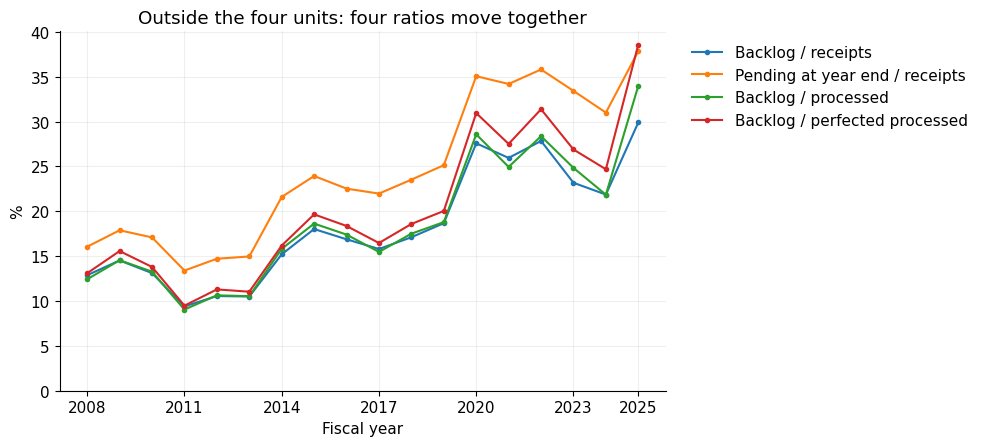

,Backlog / receipts,Pending at year end / receipts,Backlog / processed,Backlog / perfected processed,Backlog / pending at year end
2008,12.9,16.0,12.4,13.1,80.2
2009,14.5,17.9,14.5,15.6,81.2
2010,13.1,17.1,13.3,13.8,76.7
2011,9.4,13.4,9.0,9.5,70.1
2012,10.6,14.7,10.6,11.3,71.7
2013,10.5,15.0,10.5,11.0,70.2
2014,15.2,21.6,15.8,16.2,70.4
2015,18.0,23.9,18.6,19.7,75.3
2016,16.9,22.5,17.4,18.4,74.9
2017,15.8,22.0,15.5,16.5,71.9


,Perfected requests as % of processed requests
2008,94.9
2009,93.4
2010,96.2
2011,95.4
2012,94.2
2013,95.5
2014,97.8
2015,94.8
2016,94.8
2017,94.0


Backlog / perfected processed: removing any single unit leaves an average increase of at least 10.5 pp (removing DOJ) and a separation of at least 1.7 pp (removing NARA)


In [6]:
# Section 6: a second measure that does not depend on how agencies define backlog
# Perfected requests processed: Tables 16-18 (Section VII counts perfected requests only; Section V counts all requests)
PERF=[c for c in G[0] if c[:3] in ('16_','17_','18_') and 'TimeIncrementProcessedQuantity[' in c]
assert len(PERF)==39
second=pd.DataFrame({'Backlog / receipts':series([BLR],[REC],ni),'Pending at year end / receipts':series([PEND],[REC],ni),
                     'Backlog / processed':series([BLR],[PRO],ni),'Backlog / perfected processed':series([BLR],PERF,ni),
                     'Backlog / pending at year end':series([BLR],[PEND],ni)})
chart(second.iloc[:,:4],'Outside the four units: four ratios move together','%',ylim=(0,None))
display(second.round(1))
s2=second.round(1)
assert s2.loc[[2013,2019,2020,2025],'Pending at year end / receipts'].tolist()==[15.0,25.1,35.1,37.8]
assert s2.loc[[2019,2020],'Backlog / processed'].tolist()==[18.8,28.6]
assert [s2['Backlog / pending at year end'].min(),s2['Backlog / pending at year end'].max()]==[69.4,81.2]
# The perfected-only denominator
perf_share=pd.Series({y:100*sum(tot(G,c,y,ni) for c in PERF)/tot(G,PRO,y,ni) for y in YR})
display(perf_share.round(1).to_frame('Perfected requests as % of processed requests'))
assert [round(perf_share.loc[2014:2019].min(),1),round(perf_share.loc[2014:2019].max(),1)]==[93.8,97.8] and perf_share.loc[[2024,2025]].round(1).tolist()==[88.5,88.1]
assert not any((num(r[PRO]) or 0)>0 and all(num(r[c]) is None for c in PERF) for r in G if ni(r))   # no unit-year leaves Tables 16-18 entirely blank
bp=second['Backlog / perfected processed']
assert [round(bp.loc[2014:2019].mean(),1),round(bp.loc[2020:2025].mean(),1),round(bp.loc[2020:2025].mean()-bp.loc[2014:2019].mean(),1),round(bp.loc[2020:2025].min()-bp.loc[2008:2019].max(),1)]==[18.2,30.0,11.8,4.6]
lo_p=removals([BLR],PERF,ni)
gp=(lo_p.loc[2020:2025].mean()-lo_p.loc[2014:2019].mean()).drop('Baseline'); spp=(lo_p.loc[2020:2025].min()-lo_p.loc[2008:2019].max()).drop('Baseline')
assert lo_p.shape[1]-1==590 and round(gp.min(),1)==10.5 and gp.idxmin()=="('ag', 'DOJ')" and round(spp.min(),1)==1.7 and spp.idxmin()=="('ag', 'NARA')"
bpv=series([BLR],PERF,pops['Also without VBA and DHS PRIV'])
assert round(bpv.loc[2020:2025].mean()-bpv.loc[2014:2019].mean(),1)==18.4
print(f'Backlog / perfected processed: removing any single unit leaves an average increase of at least {gp.min():.1f} pp (removing DOJ) and a separation of at least {spp.min():.1f} pp (removing NARA)')

**Section 6:**
- Pending at year end ÷ receipts moves the same way: 15.0% in FY2013, 25.1% in FY2019, 35.1% in FY2020 and 37.8% in FY2025. Backlog ÷ processed does too (18.8% in FY2019, 28.6% in FY2020).
- Backlog as a share of requests pending at year end stays between 69.4% and 81.2% in all 18 years, with no drift: the rise shows in both measures, not only in backlog. The reports cannot show whether agencies changed how they count.
- **On a perfected-only denominator the rise is larger:** only perfected requests can be backlogged, but receipts and processed requests also include non-perfected ones, which are becoming more common. Perfected requests were 93.8%–97.8% of processed requests in FY2014–19 and only 88.5% and 88.1% in FY2024–25 (Tables 16–18; no unit-year with processed requests leaves all three tables blank, so this is not missing reporting). Backlog ÷ perfected processed requests averages 18.2% in FY2014–19 and 30.0% in FY2020–25, an increase of 11.8 points; the lowest FY2020–25 value is 4.6 points above the highest FY2008–19 value. After removing any single unit, the average increase is at least 10.5 (removing all of DOJ) and the separation at least 1.7 (removing NARA). Without VBA and PRIV the increase is 18.4 points (14.1 on the original measure). The 9.1 points is therefore the smaller of the two figures (a check of the choice of denominator, not proof of a lower bound), consistent with Storyline 1's finding that more requests are closed without records being processed.

## 7. How much higher, and how robust?

"Every year is higher" leans too heavily on the two years nearest the boundary, so compare the averages of FY2014–19 and FY2020–25, remove each unit in turn, and recalculate without the latest year, FY2025. FY2014–19 is a recent reference period of equal length; FY2008–19 checks the choice of starting point.

In [7]:
# Section 7: how much higher, and how robust? (single-unit removal, duplicates removed)
s=removals([BLR],[REC],ni)
print('Distinct single-unit removals:',s.shape[1]-1); assert s.shape[1]-1==590
gap=s.loc[2020:2025].mean()-s.loc[2014:2019].mean()
gap24=s.loc[2020:2024].mean()-s.loc[2014:2019].mean()
assert round(gap['Baseline'],1)==9.1 and round(gap.min(),1)==8.0
assert round(gap24['Baseline'],1)==8.3 and round(gap24.min(),1)==7.0
separation=s.loc[2020:2025].min()-s.loc[2008:2019].max()
assert round(separation.min(),1)==0.8 and separation.idxmin()=="('ag', 'NARA')"
no_nara_s=s["('ag', 'NARA')"]
assert [round(no_nara_s.loc[2008:2019].max(),1),no_nara_s.loc[2008:2019].idxmax(),round(no_nara_s.loc[2020:2025].min(),1),no_nara_s.loc[2020:2025].idxmin()]==[21.1,2019,21.8,2024]
print(f'Without NARA: highest FY2008–19 value {no_nara_s.loc[2008:2019].max():.1f}% (FY2019); lowest FY2020–25 value {no_nara_s.loc[2020:2025].min():.1f}% (FY2024)')
display(pd.DataFrame({'Average increase through 2025':gap,'Average increase through 2024':gap24,'Lowest later year minus highest earlier year':separation}).sort_values('Average increase through 2025').head(8).rename(index=unit_label).round(2))
long_gap=s.loc[2020:2025].mean()-s.loc[2008:2019].mean()
assert round(long_gap['Baseline'],1)==11.7 and round(long_gap.min(),1)==9.9
assert round(stages['FY2020–25']/stages['FY2014–19'],2)==1.54
pooled_gap=pooled(ni,2020,2025)-pooled(ni,2014,2019)
assert round(pooled_gap,2)==9.08 and round(pooled_gap,1)==round(gap['Baseline'],1)==9.1
print('Pooled difference:',round(pooled_gap,2),'pp; difference of yearly-ratio averages:',round(gap['Baseline'],2),'pp')

Distinct single-unit removals: 590
Without NARA: highest FY2008–19 value 21.1% (FY2019); lowest FY2020–25 value 21.8% (FY2024)


,Average increase through 2025,Average increase through 2024,Lowest later year minus highest earlier year
agency DOJ,8.04,7.00,2.69
agency DoD,8.25,7.49,2.19
component DOJ/BOP,8.35,7.56,2.72
agency NARA,8.46,7.64,0.77
component DoD/USCENTCOM,8.65,7.81,3.07
agency DOI,8.67,7.84,3.26
component HHS/OS,8.67,7.99,3.13
agency CIA,8.74,8.00,2.97


Pooled difference: 9.08 pp; difference of yearly-ratio averages: 9.1 pp


**Section 7:**
- The FY2020–25 average is **9.1 points** above FY2014–19 (16.9% to 26.0%, about 1.5 times). After removing any single unit (590 removals) it is at least **8.0 points**; without FY2025 it is **8.3 points**, and at least **7.0**. With FY2008–19 as the reference, the difference is 11.7 points, at least 9.9.
- Dividing six-year totals instead, the difference is 9.08 points, against 9.10 for the yearly averages; both round to 9.1.
- "Every year from FY2020 is above every earlier year" has a margin of only **0.8 points** at its tightest (removing NARA), so the finding uses the average difference instead.

**When the following year's report gives different prior-year figures:** Table XII.D of the following year's report lists the previous year's backlog and receipts. The handbook asks agencies to enter here the number "reported … [in] the prior year's Annual FOIA Report" (receipts from Section V.A, backlog from Section XII.A), so by rule the two should be identical; there is no such thing as a revision in this table. Where they differ, one of the two reports is wrong, and the tables do not say which. The following-year figures are therefore used only as an alternative set, not as more accurate ones. Method: the prior-year figures in the following year's Tables 29 and 30 are matched to the original figures by reporting-unit name, replacing backlog, and then backlog and receipts; units that cannot be matched (for example after a renaming) or missing values keep the original figures.

,Fiscal year,Unit,Original backlog,Following-year report
0,2014,VA/VBA,380,1101
1,2015,DOS/DOS - Main,20622,11722
2,2015,NARA/Agency Overall,8325,4396
3,2017,VA/VBA,1942,2885
4,2018,DOJ/OIP,525,1926
5,2021,NARA/Agency Overall,4369,9971
6,2023,VA/VBA,219,10893


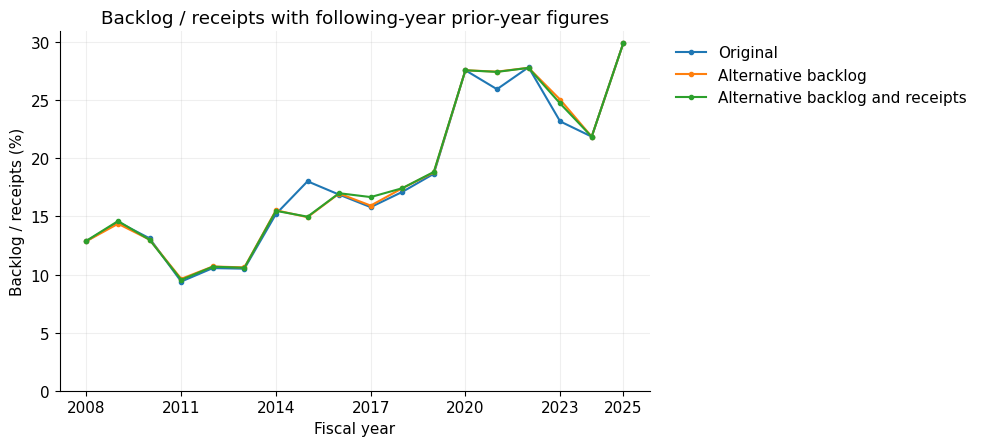

Receipts: following-year figures that differ by 5,000 or more


,Fiscal year,Unit,Original receipts,Following-year report
0,2009,HHS/FDA,10337,4880
1,2017,VA/VHA,17653,1449
2,2023,VA/VBA,61658,68244


,Later minimum minus earlier maximum,FY2020–25 mean minus FY2014–19 mean
Original,3.19,9.10
Alternative backlog,3.08,10.01
Alternative backlog and receipts,3.03,9.82


In [8]:
revisions,revised=backlog_revisions()
revised=revised.rename(columns={'Revised backlog':'Alternative backlog','Revised backlog and receipts':'Alternative backlog and receipts'})
assert len(revisions)==7
display(revisions.astype({'Original backlog':int,'Following-year report':int}))
chart(revised,'Backlog / receipts with following-year prior-year figures','Backlog / receipts (%)',ylim=(0,None))
revision_summary=pd.DataFrame({'Later minimum minus earlier maximum':revised.loc[2020:2025].min()-revised.loc[2008:2019].max(),'FY2020–25 mean minus FY2014–19 mean':revised.loc[2020:2025].mean()-revised.loc[2014:2019].mean()})
assert revision_summary.round(2).values.tolist()==[[3.19,9.10],[3.08,10.01],[3.03,9.82]]
assert revised.loc[[2015,2021,2023]].round(1).values.tolist()==[[18.0,14.9,15.0],[25.9,27.5,27.4],[23.2,25.1,24.7]]
# Three of the seven following-year figures equal that unit's requests pending at the start of the following year
PSTART=col('01','PendingAtStart')
start_pending=lambda y,u:tot(G,PSTART,y,lambda r,u=u:COK(r)==u)
three=[(2015,'DOS/DOS - Main'),(2015,'NARA/Agency Overall'),(2021,'NARA/Agency Overall')]
rv=revisions.set_index(['Fiscal year','Unit'])
assert [int(rv.loc[k,'Following-year report']) for k in three]==[11722,4396,9971]==[int(start_pending(y+1,u)) for y,u in three]
# How much of the FY2015 and FY2021 change (backlog replaced) these units account for
for y in (2015,2021):
    whole=(revised.loc[y,'Alternative backlog']-revised.loc[y,'Original'])/100*tot(G,REC,y,ni)
    part=sum(rv.loc[(yy,u),'Following-year report']-rv.loc[(yy,u),'Original backlog'] for yy,u in three if yy==y)
    assert part/whole>0.9
assert [int(rv.loc[k,'Following-year report']-rv.loc[k,'Original backlog']) for k in three]==[-8900,-3929,5602]

# The receipts that were replaced as well: differences of 5,000 or more; and how many unit-years were matched
def unit_totals(y,c):
    out=defaultdict(float)
    for r in G:
        if r['Fiscal Year']==str(y) and ni(r):
            v=num(r[c])
            if v is not None: out[COK(r)]+=v
    return out
PB,PR,PP=col('30','BacklogLastYear'),col('29','ItemsReceivedLastYear'),col('29','ItemsProcessedLastYear')
rec_rev=[]; n_match=n_diff=n_unmatched=0
for y in range(2008,2025):
    b,r=unit_totals(y,BLR),unit_totals(y,REC); nb,nr=unit_totals(y+1,PB),unit_totals(y+1,PR)
    common=b.keys()&nb.keys(); n_match+=len(common); n_diff+=sum(nb[k]!=b[k] for k in common); n_unmatched+=len(b.keys()-nb.keys())
    rec_rev+=[(y,k,r[k],nr[k]) for k in r.keys()&nr.keys() if abs(nr[k]-r[k])>=5000]
rec_rev=pd.DataFrame(sorted(rec_rev),columns=['Fiscal year','Unit','Original receipts','Following-year report']).astype({'Original receipts':int,'Following-year report':int})
print('Receipts: following-year figures that differ by 5,000 or more'); display(rec_rev)
assert rec_rev.values.tolist()==[[2009,'HHS/FDA',10337,4880],[2017,'VA/VHA',17653,1449],[2023,'VA/VBA',61658,68244]]
assert (n_match,n_diff,n_unmatched)==(6880,594,220)
assert revised.loc[2017].round(1).tolist()==[15.8,15.9,16.7]
vha=lambda r:AGK(r)=='VA' and r['Component']=='VHA'
assert [int(tot(G,PP,2018,vha)),int(tot(G,PRO,2017,vha))]==[17710,17728]   # VHA's FY2018 report: FY2017 processed is close to the original, received is not
display(revision_summary.round(2))

**Seven** matched prior-year backlog figures differ by 500 or more, some up and some down. After replacement:
- The FY2020–25 average is 9.10 points above FY2014–19 as originally reported, 10.01 with backlog replaced, and 9.82 with backlog and receipts replaced: **the gap gets slightly larger**, because replacement lowers some earlier years and raises some later ones (for example FY2015 falls from 18.0% to 14.9% with backlog replaced, FY2021 rises from 25.9% to 27.5%, and FY2023 from 23.2% to 25.1%).
- The lowest FY2020–25 value is still 3.03–3.19 points above the highest FY2008–19 value.
- **In three cases the nature of the mismatch is visible:** in three of the seven cases the following year's "prior-year backlog" equals that unit's requests pending at the start of the following year: 11,722 for DOS Main FY2015, 4,396 for NARA FY2015 and 9,971 for NARA FY2021. These look like re-counted pending inventories entered as prior-year backlog, not corrected backlog counts. More than 90% of the FY2015 fall (to 14.9%) and the FY2021 rise (to 27.5%) comes from these cases: DOS −8,900 and NARA −3,929 in FY2015, NARA +5,602 in FY2021. The replaced series is therefore only a reference; the main finding uses the original figures.
- **How many were matched:** in FY2008–24, 6,880 unit-years can be matched to the following year's report; 594 of them have a backlog figure different from the original, and 220 cannot be matched and keep the original. FY2025 has no following year.
- **When receipts are replaced too:** three receipts figures differ by 5,000 or more (last table above): HHS's FDA in FY2009 (10,337 to 4,880), VA's VHA in FY2017 (17,653 to 1,449) and VA's VBA in FY2023 (61,658 to 68,244). The VHA case looks like an entry error in the following year's report: in the same table its FY2017 processed figure is 17,710, almost the original 17,728, while the received figure is off by more than ten times. It is why the "backlog and receipts" line is higher in FY2017 (16.7% against 15.9% with backlog only).

## 8. Where is the backlog?

Finally, where government backlog is concentrated, and why the four units are not the main story.

In [9]:
# Section 8: where the backlog is (FY2025)
blv=tot(G,BLR,2025)
cbp=lambda r:AGK(r)=='DHS' and r['Component']=='CBP'; usc=lambda r:AGK(r)=='DHS' and r['Component']=='USCIS'; dosm=lambda r:AGK(r)=='DOS' and r['Component']=='DOS - Main'
where=pd.DataFrame({k:{'FY2025 backlog':tot(G,BLR,2025,f),'Share of government backlog (%)':100*tot(G,BLR,2025,f)/blv} for k,f in [('DHS CBP',cbp),('DHS PRIV',isPRIV),('DOS Main',dosm)]}).T
display(where.round(1).astype({'FY2025 backlog':int}))
assert where['FY2025 backlog'].astype(int).tolist()==[96303,48433,22678] and where['Share of government backlog (%)'].round(1).tolist()==[28.3,14.3,6.7]
assert round(where['Share of government backlog (%)'].sum(),1)==49.3
assert [round(100*tot(G,BLR,2025,ni)/blv,1),round(100*tot(G,REC,2025,ni)/tot(G,REC,2025),1)]==[65.6,43.6]
assert scopes['Four units'].loc[[2008,2014,2019]].round(1).tolist()==[65.7,32.1,8.8]
assert [int(tot(G,BLR,y,usc)) for y in (2020,2021)]==[20344,1599] and [int(tot(G,BLR,y,cbp)) for y in (2023,2024)]==[21444,110271]
# FY2025 on its own
assert [int(tot(G,BLR,y,ni)) for y in (2024,2025)]==[135530,222820] and [int(tot(G,BLR,y,isPRIV)) for y in (2024,2025)]==[4074,48433]
assert int(tot(G,BLR,2025,ni)-tot(G,BLR,2024,ni))==87290 and int(tot(G,BLR,2025,isPRIV)-tot(G,BLR,2024,isPRIV))==44359
proc_rate=pd.Series({y:100*tot(G,PRO,y,ni)/tot(G,REC,y,ni) for y in YR})
assert round(proc_rate[2025],1)==88.0 and proc_rate.idxmin()==2025
print(f"FY2025 outside the four units: processed / received = {proc_rate[2025]:.1f}% (lowest of the 18 years)")

,FY2025 backlog,Share of government backlog (%)
DHS CBP,96303,28.3
DHS PRIV,48433,14.3
DOS Main,22678,6.7


FY2025 outside the four units: processed / received = 88.0% (lowest of the 18 years)


**Section 8:**
- Government-wide backlog in FY2025 is 339,756: CBP 96,303 (28.3%), PRIV 48,433 (14.3%) and DOS Main 22,678 (6.7%), together 49.3%. Outside the four units accounts for 65.6% of government backlog and 43.6% of receipts.
- **The four units' own ratio swings widely:** 65.7% in FY2008, 32.1% in FY2014, 8.8% in FY2019. USCIS backlog was 20,344 in FY2020 and 1,599 in FY2021; CBP's was 21,444 in FY2023 and 110,271 in FY2024. With swings this large within a year and many reporting questions, they are not the main story.
- **FY2025 on its own:** backlog outside the four units rose by 87,290 in one year (135,530 to 222,820), 44,359 of it at PRIV (4,074 to 48,433). That year, processed ÷ received outside the four units was 88.0%, the lowest of the 18 years. FY2025 has no following-year report to check against yet.

## 9. The resulting story

**In one sentence:** outside USCIS, CBP, ICE and EOIR, year-end backlog relative to annual receipts climbed from about 10% in FY2011–13 to 26.0% in FY2020–25; the FY2020–25 average is 9.1 points above FY2014–19, and at least 8.0 points after removing any single unit. The rise is mainly within agencies and broad. The government-wide ratio rose only about 3 points because the four units have low ratios and a growing share of receipts.

**Key points:**
1. **The government-wide ratio hides it (Section 2):** six-year averages of 15.7% and 18.8%. The four units have low ratios (12.8% on average in FY2020–25) and a growing share of receipts (47.3% in FY2019, 56.4% in FY2025), which dilutes the rise elsewhere.
2. **Outside the four units, a rise in stages (Section 3):** about 10% in FY2011–13, 16.9% in FY2014–19 and 26.0% in FY2020–25, with five down years out of twelve; the largest single-year rises are FY2020 (+8.9) and FY2025 (+8.0).
3. **How much, and how robust (Section 7):** 9.1 points higher on average (about 1.5 times), at least 8.0 after any single removal, 8.3 without FY2025; with following-year prior-year figures the gap is slightly larger (10.01 and 9.82).
4. **Broad and within agencies (Section 4):** 69 of 96 agencies rose (24 of the 28 with at least 6,000 receipts); split by agency, the within-agency change averages +9.20 of the +9.03 total; DoD, DOJ, HHS, DOT, DOS and Treasury each rose 11.8 to 25.8 points.
5. **The two bumps come from a few units' receipts (Section 5):** 78% of the FY2020 fall in receipts is at NARA and PRIV, while the backlog increase is spread out; the FY2023–24 dip reflects large receipts at VBA and PRIV, and without them the ratio is 27.6% or higher in every year from FY2020.
6. **A second measure agrees (Section 6):** pending at year end ÷ receipts went from 25.1% in FY2019 to 35.1% in FY2020 and 37.8% in FY2025; on a perfected-only denominator the increase is 11.8 points, larger than 9.1.

**What not to say:**
- Do not say backlog pressure is flat government-wide without the split: outside the four units it rose by about half.
- Do not present FY2020 as a break caused by a single event: the ratio had already risen 8.2 points from FY2013 to FY2019, and the annual reports do not show causes.
- Do not use "every year since FY2020 is above every earlier year" as the headline: the margin is 0.8 points after removing NARA.
- Do not read the lower FY2023–24 values as relief: they reflect larger receipts at VBA and PRIV.
- Do not call the population "non-immigration requests": it is a grouping of units, not of request topics.
- Do not lean on FY2025 alone: 44,359 of the 87,290 added backlogged requests outside the four units are at PRIV, and FY2025 has no following-year check yet.

**Leads to follow up separately:**
- DOS: backlog ÷ receipts from 90.4% to 116.2%, more than a year of receipts.
- DOJ (excluding EOIR): 29.8% to 49.9%.
- PRIV: FY2025 backlog from 4,074 to 48,433; whether PRIV belongs with the immigration-related units is undecided, and the main population keeps it.
- NARA's receipts swing sharply (FY2019–23: 67,466, 25,738, 7,725, 14,975, 62,505).
- In FY2025, processed ÷ received outside the four units was only 88.0%, the lowest of 18 years.
- Jumps in the four units' own backlog: CBP from 21,444 in FY2023 to 110,271 in FY2024; USCIS from 20,344 in FY2020 to 1,599 in FY2021.

### Methods and remaining questions

- "Outside the four units" is not "all non-immigration requests"; other agencies may also process immigration-related records. It is a grouping of units, not of request topics.
- FY2020 was observed during exploration, not specified in advance; causes such as the pandemic or staffing are not examined here.
- Sections 2 and 4 divide six-year totals; Sections 3 and 7 average the yearly ratios. The two give differences of 9.08 and 9.10 points, both 9.1 to one decimal.
- Single-unit removal drops one agency or component from all years; agencies without components count once, 590 removals in all. This differs from Storyline 1's 571 because the population differs: it includes DHS's other components and NARA, and excludes the four units.
- Prior-year figures are matched by reporting-unit name; renamed units cannot be matched and keep their original figures. FY2025 has no following year to check. The prior-year replacement and the single-unit removals were run separately, not in every combination.
- Some agencies are missing in FY2008–09 (Section 3). The annual reports are self-reported; blank cells count as zero in totals, and nothing is imputed.

### Data and reproduction

Source: `data/component_master_no_03_06_11.csv`. Table 26 backlog; Table 01 receipts, processed requests and requests pending at year end; prior-year figures in the following year's Tables 29 and 30 for the replacement check. Shared functions are in `storyline_lib.py`; the main series and every figure quoted in the text are checked with assertions. This version no longer writes `S4-unmatched-reporting-labels.csv`, so running it has no side effects.